In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d
import itertools


In [6]:
def plot_confusion_matrix(labels, preds, classes=("Real", "Fake"),
                          normalize=True,
                          cmap=plt.cm.Blues,
                          ax=None):
    
    cm = confusion_matrix(labels, preds)

    if normalize:
        cm = cm.astype('float') / np.maximum(cm.sum(axis=1)[:, np.newaxis], 1)

    if ax is None:
        fig, ax = plt.subplots(figsize=(3, 3))

    im = ax.imshow(cm, interpolation='nearest', cmap=cmap,
                   vmin=0, vmax=1 if normalize else None)

    tick_marks = np.arange(len(classes))
    ax.set_xticks(tick_marks)
    ax.set_yticks(tick_marks)
    ax.set_xticklabels(classes, rotation=45)
    ax.set_yticklabels(classes)

    threshold = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        text = f"{cm[i, j]*100:.2f}%" if normalize else f"{cm[i, j]:d}"
        ax.text(j, i, text,
                ha="center",
                color="white" if cm[i, j] > threshold else "black")

    ax.set_ylabel('True label')
    ax.set_xlabel('Predicted label')

    return cm

def compute_cllr(scores, labels):
    scores = np.array(scores)
    labels = np.array(labels)
    tar = scores[labels == 1]
    non = scores[labels == 0]
    c1 = np.mean(np.log2(1 + np.exp(-tar)))
    c2 = np.mean(np.log2(1 + np.exp(non)))
    return (c1 + c2) / 2
    
def print_metrics(scores, labels, threshold=0):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)
    cllr = compute_cllr(scores, labels)
    
    preds = (scores >= threshold).astype(int)
    
    bacc = balanced_accuracy_score(preds, labels)
    acc = accuracy_score(preds, labels)
    prec = precision_score(labels, preds)
    rec = recall_score(labels, preds)
    f1 = f1_score(labels, preds)

    return rocauc, eer, cllr, bacc, acc, prec, rec, f1

def analyze_ensemble(all_logLR, labels, threshold=0):
    rocauc, eer, cllr, bacc, acc, prec, rec, f1 = print_metrics(all_logLR, labels, threshold)
    
    header = f"{'AUC%':>8} {'EER%':>8} {'Cllr':>8} | {'B.Acc.':>8} {'Acc.':>8} {'Prec.':>8} {'Recall':>8} {'F1':>8}"
    print(header)
    print(f"{rocauc*100:>8.2f} "
          f"{eer*100:>8.2f} "
          f"{cllr:>8.4f} |"
          f"{bacc*100:>8.2f} "
          f"{acc*100:>8.2f} "
          f"{prec*100:>8.2f} "
          f"{rec*100:>8.2f} "
          f"{f1*100:>8.2f}")

    preds = (all_logLR >= threshold).astype(int)

    # --- new: side-by-side ROC (left) + CM (right)
    fig, (ax_roc, ax_cm) = plt.subplots(1, 2, figsize=(6, 3))

    fpr, tpr, _ = roc_curve(labels, all_logLR)
    ax_roc.plot(fpr, tpr)
    ax_roc.plot([0, 1], [0, 1], linestyle='--')
    ax_roc.set_xlabel('FPR')
    ax_roc.set_ylabel('TPR')
    ax_roc.set_title(f'ROC (AUC={rocauc:.3f})')

    plot_confusion_matrix(labels, preds, ax=ax_cm)

    plt.tight_layout()


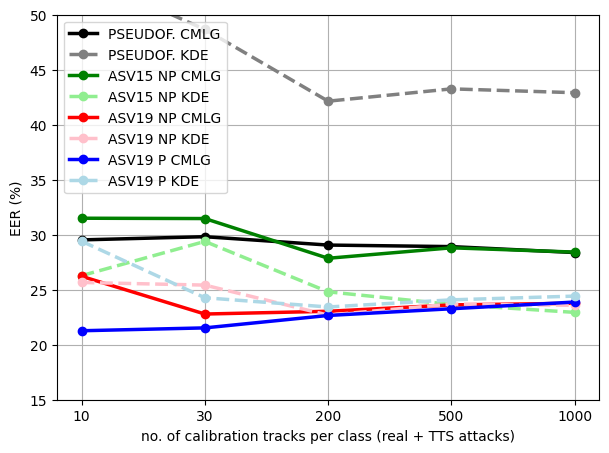

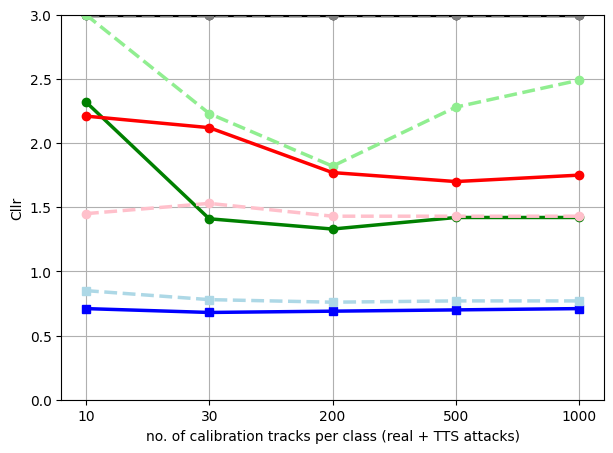

In [8]:
# X Labels
x_labels = [10, 30, 200, 500, 1000]
x_pos = range(len(x_labels))

# ---- EER (%) ----
pseudo_cmlg = [29.53, 29.82, 29.06, 28.92, 28.38]
pseudo_kde = [53.67, 48.66, 42.14, 43.26, 42.91]

asv15_cmlg = [31.50, 31.47, 27.86, 28.81, 28.42]
asv15_kde = [26.28, 29.39, 24.81, 23.66, 22.94]

asv19_no_pool_cmlg = [26.22, 22.79, 23.04, 23.62, 23.77]
asv19_no_pool_kde  = [25.66, 25.42, 22.69, 23.7, 23.58]

asv19_pool_cmlg = [21.27, 21.53, 22.66, 23.27, 23.88]
asv19_pool_kde  = [29.41, 24.27, 23.43, 24.08, 24.42]

plt.figure(figsize=(7, 5))

plt.plot(x_pos, pseudo_cmlg, '-', marker='o', linewidth=2.5, color='black', label="PSEUDOF. CMLG")
plt.plot(x_pos, pseudo_kde, '--', marker='o', linewidth=2.5, color='grey', label="PSEUDOF. KDE")

plt.plot(x_pos, asv15_cmlg, '-', marker='o', linewidth=2.5, color='green', label="ASV15 NP CMLG")
plt.plot(x_pos, asv15_kde, '--', marker='o', linewidth=2.5, color='lightgreen', label="ASV15 NP KDE")

plt.plot(x_pos, asv19_no_pool_cmlg, '-', marker='o', linewidth=2.5, color='red', label="ASV19 NP CMLG")
plt.plot(x_pos, asv19_no_pool_kde,  '--', marker='o', linewidth=2.5, color='pink', label="ASV19 NP KDE")

plt.plot(x_pos, asv19_pool_cmlg, '-', marker='o', linewidth=2.5, color='blue', label="ASV19 P CMLG")
plt.plot(x_pos, asv19_pool_kde,  '--', marker='o', linewidth=2.5, color='lightblue', label="ASV19 P KDE")

plt.xticks(x_pos, x_labels)
plt.ylim(15, 50)
plt.xlabel("no. of calibration tracks per class (real + TTS attacks)")
plt.ylabel("EER (%)")
plt.legend()
plt.grid(True)
plt.show()


# ---- Cllr ----
pseudo_cmlg_cllr = [3.00, 3.00, 3.00, 3.00, 3.00]
pseudo_kde_cllr = [3.00, 3.00, 3.00, 3.00, 3.00]

asv15_cmlg_cllr = [2.32, 1.41, 1.33, 1.42, 1.42]
asv15_kde_cllr = [3.0, 2.23, 1.82, 2.28, 2.49]

asv19_no_pool_cmlg_cllr = [2.21, 2.12, 1.77, 1.70, 1.75]
asv19_no_pool_kde_cllr  = [1.45, 1.53, 1.43, 1.43, 1.43]

asv19_pool_cmlg_cllr = [0.71, 0.68, 0.69, 0.70, 0.71]
asv19_pool_kde_cllr  = [0.85, 0.78, 0.76, 0.77, 0.77]

plt.figure(figsize=(7, 5))

plt.plot(x_pos, pseudo_cmlg_cllr, '-', marker='o', linewidth=2.5, color='black', label="PSEUDOF. CMLG")
plt.plot(x_pos, pseudo_kde_cllr, '--', marker='o', linewidth=2.5, color='grey', label="PSEUDOF. KDE")

plt.plot(x_pos, asv15_cmlg_cllr, '-', marker='o', linewidth=2.5, color='green', label="ASV15 NP CMLG")
plt.plot(x_pos, asv15_kde_cllr, '--', marker='o', linewidth=2.5, color='lightgreen', label="ASV15 NP KDE")

plt.plot(x_pos, asv19_no_pool_cmlg_cllr, '-', marker='o', linewidth=2.5, color='red', label="ASV19 NP CMLG")
plt.plot(x_pos, asv19_no_pool_kde_cllr,  '--', marker='o', linewidth=2.5, color='pink', label="ASV19 NP KDE")

plt.plot(x_pos, asv19_pool_cmlg_cllr, '-', marker='s', linewidth=2.5, color='blue', label="ASV19 P CMLG")
plt.plot(x_pos, asv19_pool_kde_cllr,  '--', marker='s', linewidth=2.5, color='lightblue', label="ASV19 P KDE")

plt.xticks(x_pos, x_labels)
plt.ylim(0, 3)
plt.xlabel("no. of calibration tracks per class (real + TTS attacks)")
plt.ylabel("Cllr")
#plt.legend()
plt.grid(True)
plt.show()

# ASVspoof 2019

/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_30

Ensemble performance (PLAIN SUM):
    AUC%     EER%     Cllr |   B.Acc.     Acc.    Prec.   Recall       F1
   86.94    21.59   0.6823 |   60.42    65.21    98.46    62.04    76.12



,-,A01,A02,A03,A04,A07,A08,A09,A10,A11,A12
Exp 0,0.00,0.01,-0.04,-0.02,0.03,-0.04,-0.01,-0.04,-0.01,-0.01,-0.00
Exp 1,-0.19,0.03,0.29,0.47,-0.36,-0.31,0.20,0.38,-0.28,0.11,-0.43
Exp 2,-0.39,0.00,-0.19,0.57,-0.37,0.21,0.52,0.91,0.01,0.15,-0.13
Exp 3,-0.52,-0.80,-0.47,0.51,1.69,-0.35,-0.03,1.21,-0.32,1.48,2.04
Exp 4,-0.09,0.39,0.15,0.24,-0.14,0.04,0.39,0.03,-0.10,-0.06,-0.11


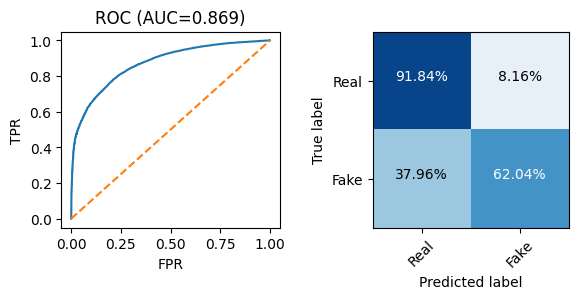

In [32]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/CMLG/5_experts"

specific_path = 'Cset_ASV19_pooled_30'
full_path = os.path.join(rootpath, specific_path)
print(full_path)

labels = np.load(os.path.join(full_path, "labels.npy"))
logLR_scores = np.load(os.path.join(full_path, "scores_per_expert.npy"))
attack_ids = np.load(os.path.join(full_path, "attack_ids.npy"))

#attack_ids = attack_ids[0, :]

# Print ensemble performance metrics & confusion matrix
print()
print("Ensemble performance (PLAIN SUM):")
sum_logLR_scores = np.sum(logLR_scores, axis=0)  # sum expert contributions
analyze_ensemble(sum_logLR_scores, labels, threshold=0)
print()


# Compute individual logLR
unique_attacks = np.unique(attack_ids)
mean_scores_per_attack = {}
for attack in unique_attacks:
    mask = (attack_ids == attack)
    mask = mask.squeeze()  # (1, Nsamples) -> (Nsamples)
    mean_scores_per_attack[attack] = np.mean(logLR_scores[:, mask], axis=1)

# Visualize table
df = pd.DataFrame({a: mean_scores_per_attack[a] for a in unique_attacks})
df.index = [f"Exp {i}" for i in range(logLR_scores.shape[0])]
df.round(2)

## ASVspoof 5

/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_30

Ensemble performance (PLAIN SUM):
    AUC%     EER%     Cllr |   B.Acc.     Acc.    Prec.   Recall       F1
   64.16    39.40   1.0042 |   56.65    46.65    88.67    38.14    53.33



,A01,A02,A03,A04,A05,A06,A07,A08,A09,A10,A11,A12,A14,A17,A19,A21,A22,A28,A29,bonafide
Exp 0,-0.00,-0.00,-0.01,-0.01,-0.01,-0.01,-0.03,-0.03,-0.03,-0.03,-0.02,0.03,0.01,-0.02,0.02,-0.03,-0.02,-0.01,-0.02,-0.01
Exp 1,0.44,0.52,0.50,0.31,0.41,0.45,0.76,0.33,0.36,0.36,0.19,-0.58,0.12,0.16,-0.28,0.49,0.32,0.08,0.28,0.04
Exp 2,0.10,0.10,0.14,0.17,0.21,0.17,0.28,0.00,0.20,0.20,-0.01,-0.37,0.17,0.02,-0.17,0.12,0.22,0.13,0.23,0.01
Exp 3,-0.77,-0.81,-0.77,-0.72,-0.72,-0.78,-0.85,-0.80,0.11,0.11,2.02,-0.20,-0.92,-0.61,-0.28,0.08,0.57,-0.44,-0.60,-0.60
Exp 4,-0.18,-0.22,-0.20,-0.23,-0.28,-0.27,-0.27,-0.12,0.14,0.14,-0.10,-0.12,-0.32,-0.17,-0.13,-0.00,0.15,-0.13,-0.22,-0.07


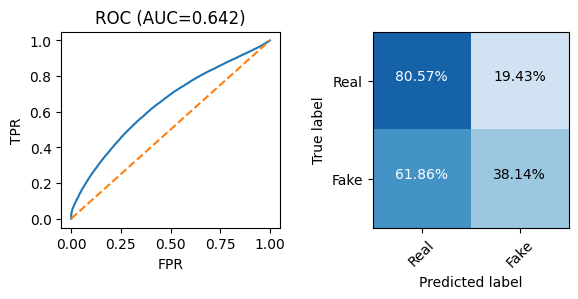

In [58]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_mix/CMLG/5_experts"
specific_path = 'Cset_ASV19_pooled_30'

full_path = os.path.join(rootpath, specific_path)
print(full_path)

labels = np.load(os.path.join(full_path, "labels.npy"))
logLR_scores = np.load(os.path.join(full_path, "scores_per_expert.npy"))
attack_ids = np.load(os.path.join(full_path, "attack_ids.npy"))


# Print ensemble performance metrics & confusion matrix
print()
print("Ensemble performance (PLAIN SUM):")
sum_logLR_scores = np.sum(logLR_scores, axis=0)  
analyze_ensemble(sum_logLR_scores, labels, threshold=0)
print()


# Compute individual logLR
unique_attacks = np.unique(attack_ids)
mean_scores_per_attack = {}
for attack in unique_attacks:
    mask = (attack_ids == attack)
    mask = mask.squeeze()  # (1, Nsamples) -> (Nsamples)
    mean_scores_per_attack[attack] = np.mean(logLR_scores[:, mask], axis=1)

# Visualize table
df = pd.DataFrame({a: mean_scores_per_attack[a] for a in unique_attacks})
df.index = [f"Exp {i}" for i in range(logLR_scores.shape[0])]
df.round(2)

# SpoofCeleb

/home/smg/v-viola/moe_antideepfake/results/Ensemble/sc/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_30

Ensemble performance (PLAIN SUM):
    AUC%     EER%     Cllr |   B.Acc.     Acc.    Prec.   Recall       F1
   65.61    38.56   1.0771 |   52.50    31.04    98.24    27.58    43.07



,a00,a01,a02,a03,a04,a05,a06,a07,a08,a09
Exp 0,-0.01,-0.00,-0.01,-0.01,-0.01,-0.00,-0.00,0.03,-0.01,-0.01
Exp 1,0.51,0.21,0.17,0.25,0.21,0.07,0.36,-0.09,0.26,0.42
Exp 2,-0.09,0.18,0.32,0.13,0.16,-0.04,-0.24,-0.09,0.18,0.01
Exp 3,-1.13,-0.77,0.79,-0.64,-0.66,-1.19,-1.00,-1.06,-1.01,-0.89
Exp 4,-0.33,0.15,0.18,0.17,0.06,0.06,-0.02,2.68,0.08,-0.05


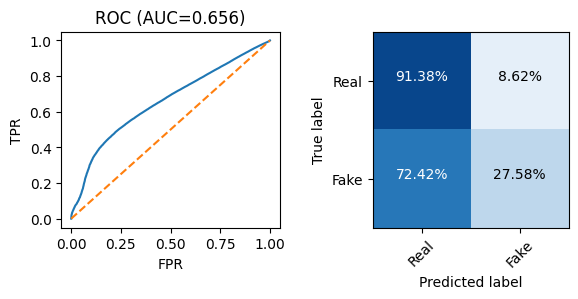

In [56]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/sc/experts_trained_on_mix/CMLG/5_experts"
specific_path = 'Cset_ASV19_pooled_30'

full_path = os.path.join(rootpath, specific_path)
print(full_path)

labels = np.load(os.path.join(full_path, "labels.npy"))
logLR_scores = np.load(os.path.join(full_path, "scores_per_expert.npy"))
attack_ids = np.load(os.path.join(full_path, "attack_ids.npy"))


# Print ensemble performance metrics & confusion matrix
print()
print("Ensemble performance (PLAIN SUM):")
sum_logLR_scores = np.sum(logLR_scores, axis=0)  
analyze_ensemble(sum_logLR_scores, labels, threshold=0)
print()


# Compute individual logLR
unique_attacks = np.unique(attack_ids)
unique_attacks = unique_attacks[:10]

mean_scores_per_attack = {}
for attack in unique_attacks:
    mask = (attack_ids == attack)
    mask = mask.squeeze()  # (1, Nsamples) -> (Nsamples)
    mean_scores_per_attack[attack] = np.mean(logLR_scores[:, mask], axis=1)

# Visualize table
df = pd.DataFrame({a: mean_scores_per_attack[a] for a in unique_attacks})
df.index = [f"Exp {i}" for i in range(logLR_scores.shape[0])]
df.round(2)

# MLAAD

/home/smg/v-viola/moe_antideepfake/results/Ensemble/mlaad/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_30_REAL_from_ASV19_eval

Ensemble performance (PLAIN SUM):
    AUC%     EER%     Cllr |   B.Acc.     Acc.    Prec.   Recall       F1
   83.23    24.97   0.7661 |   61.86    57.79    97.00    51.19    67.01



,-,Mars5,MatchaTTS,MeloTTS,Metavoice-1B,OpenVoiceV2,WhisperSpeech,e2-tts,f5-tts,facebook_mms-tts-eng
Exp 0,0.00,-0.02,-0.01,-0.01,-0.02,-0.02,-0.02,-0.02,-0.02,-0.02
Exp 1,-0.19,0.18,0.24,-0.07,-0.36,0.03,0.22,0.17,0.20,0.34
Exp 2,-0.39,0.10,0.26,0.15,0.05,0.19,0.08,0.15,0.21,-0.01
Exp 3,-0.52,-0.18,0.36,0.61,0.48,0.31,-0.19,-0.04,0.02,0.09
Exp 4,-0.09,0.01,-0.03,0.01,0.10,-0.06,0.01,0.00,0.09,-0.11


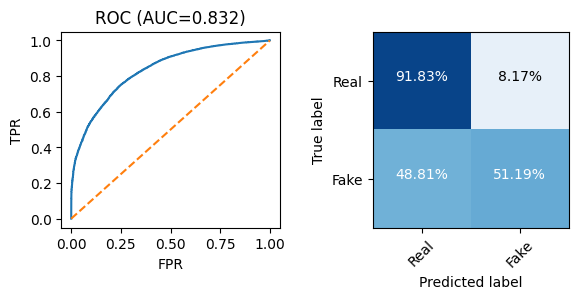

In [57]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/mlaad/experts_trained_on_mix/CMLG/5_experts"
#specific_path = 'Cset_ASV19_pooled_30'
specific_path = 'Cset_ASV19_pooled_30_REAL_from_ASV19_eval'

full_path = os.path.join(rootpath, specific_path)
print(full_path)

labels = np.load(os.path.join(full_path, "labels.npy"))
logLR_scores = np.load(os.path.join(full_path, "scores_per_expert.npy"))
attack_ids = np.load(os.path.join(full_path, "attack_ids.npy"))


# Print ensemble performance metrics & confusion matrix
print()
print("Ensemble performance (PLAIN SUM):")
sum_logLR_scores = np.sum(logLR_scores, axis=0)  
analyze_ensemble(sum_logLR_scores, labels, threshold=0)
print()


# Compute individual logLR
unique_attacks = np.unique(attack_ids)
unique_attacks = unique_attacks[:10]

mean_scores_per_attack = {}
for attack in unique_attacks:
    mask = (attack_ids == attack)
    mask = mask.squeeze()  # (1, Nsamples) -> (Nsamples)
    mean_scores_per_attack[attack] = np.mean(logLR_scores[:, mask], axis=1)

# Visualize table
df = pd.DataFrame({a: mean_scores_per_attack[a] for a in unique_attacks})
df.index = [f"Exp {i}" for i in range(logLR_scores.shape[0])]
df.round(2)

# 6 experts - ASVspoof 2019
### calib -> 1000 samples per class

/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/CMLG/6_experts/Cset_ASV19_pooled

Ensemble performance (PLAIN SUM):
    AUC%     EER%     Cllr |   B.Acc.     Acc.    Prec.   Recall       F1
   80.42    28.51   0.7653 |   58.75    67.25    96.11    66.02    78.27



,-,A01,A02,A03,A04,A07,A08,A09,A10,A11,A12
Exp 0,0.02,0.05,-0.20,-0.13,0.17,-0.23,-0.03,-0.23,-0.03,-0.04,-0.02
Exp 1,-0.08,0.03,0.15,0.24,-0.16,-0.14,0.11,0.20,-0.13,0.07,-0.20
Exp 2,-0.32,0.05,-0.13,0.59,-0.30,0.24,0.54,0.90,0.06,0.19,-0.07
Exp 3,-0.40,-0.64,-0.36,0.52,1.55,-0.25,0.04,1.13,-0.22,1.37,1.86
Exp 4,-0.09,0.36,0.13,0.22,-0.13,0.04,0.35,0.02,-0.09,-0.06,-0.11
Exp 5,0.23,-0.08,0.22,0.22,-0.08,-0.09,-0.09,0.88,0.36,0.34,0.35


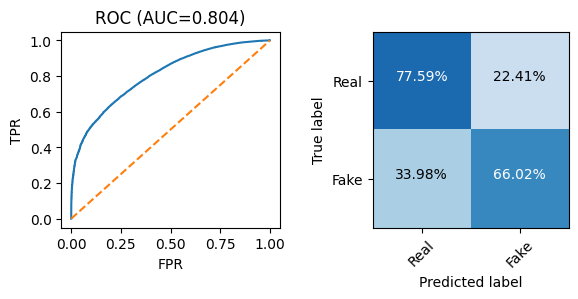

In [36]:
full_path = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/CMLG/6_experts/Cset_ASV19_pooled"
#full_path = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/KDE/6_experts/Cset_ASV19_pooled"
print(full_path)

labels = np.load(os.path.join(full_path, "labels.npy"))
logLR_scores = np.load(os.path.join(full_path, "scores_per_expert.npy"))
attack_ids = np.load(os.path.join(full_path, "attack_ids.npy"))


# Print ensemble performance metrics & confusion matrix
print()
print("Ensemble performance (PLAIN SUM):")
sum_logLR_scores = np.sum(logLR_scores, axis=0)  # sum expert contributions
analyze_ensemble(sum_logLR_scores, labels, threshold=0)
print()


# Compute individual logLR
unique_attacks = np.unique(attack_ids)
mean_scores_per_attack = {}
for attack in unique_attacks:
    mask = (attack_ids == attack)
    mask = mask.squeeze()  # (1, Nsamples) -> (Nsamples)
    mean_scores_per_attack[attack] = np.mean(logLR_scores[:, mask], axis=1)

# Visualize table
df = pd.DataFrame({a: mean_scores_per_attack[a] for a in unique_attacks})
df.index = [f"Exp {i}" for i in range(logLR_scores.shape[0])]
df.round(2)